# HMS v5 — removing the recording-boundary shortcut, and auditing the 10-minute spectrograms

**Inputs:** (1) HMS competition data (EEGs **and** `train_spectrograms`); (2) the training notebook's latest output (the v4 run, Version 5 — it holds all `*_valpred.npy` files for the 50 s and original 200 s models). GPU T4, **≈ 4.5 h** → use **Save Version → Save & Run All**. Finished runs are saved one by one and skipped on rerun (attach this notebook's output to continue).

**Why.** The shortcut-check notebook showed that 200 s models read where the recording ends from their padding, and recording length predicts the label through HMS's annotation rounds. For a journal paper two questions remain:
- **A. Is the same leak inside common pipelines?** Most HMS solutions use the provided 10-minute spectrograms. We measure how much of each spectrogram window is missing and test whether that alone predicts the expert votes.
- **B. Can it be removed, and what is the real long-context effect then?** Boundary-agnostic (BA) training for Mamba, GRU and Transformer at 200 s, plus a reweighting ablation for Mamba; then the true context gain and a shortcut-free architecture comparison.

In [1]:
import os, glob, json, math, time, random, shutil
import numpy as np
import pandas as pd

CFG = dict(
    DATA_ROOT=None,                       # None = auto-detect under /kaggle/input
    CACHE_DIR="/kaggle/working/cache",    # replaced in the v2 settings cell below
    RESULTS_DIR="/kaggle/working/results",
    FS=100,                               # target sampling rate (Hz)
    CTX_SEC=50,
    CACHE_CTX_SEC=100,
    JITTER_SEC=1.0,                       # train-time random shift of the window centre
    PATCH=25,                             # samples per token (0.25 s at 100 Hz)
    N_FOLDS=5, FOLDS=[0], SEED=42,
    MODELS=["mamba", "transformer", "gru", "cnn"],
    D_MODEL=128, N_LAYERS=4, D_STATE=64, HEADDIM=32, EXPAND=2, CHUNK=64, N_HEADS_ATTN=4,
    EPOCHS=15, BATCH=64, LR=1e-3, WD=0.05, WARMUP_FRAC=0.05, CLIP=1.0,
    TRAIN_MIN_VOTES=0,
    HIGH_VOTE=10,                         # threshold for the high-agreement evaluation subset
    NUM_WORKERS=4, AMP=True,
    USE_OFFICIAL_MAMBA2=False,
    RUN_BENCHMARK=True,
    BENCH_CTX=[50, 100, 200, 400, 600, 1200],
)

In [2]:
import pyarrow.parquet as pq
import multiprocessing as mp
from scipy.signal import butter, sosfiltfilt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, f1_score
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Sampler

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(CFG["SEED"])
MP = mp.get_context("fork")   # Kaggle is Linux; fork shares globals with workers
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEV, torch.cuda.get_device_name(0) if DEV.type == "cuda" else "")

def find_root():
    if CFG["DATA_ROOT"]:
        return CFG["DATA_ROOT"]
    for pat in ["/kaggle/input/*/train.csv", "/kaggle/input/*/*/train.csv"]:
        for h in glob.glob(pat):
            if os.path.isdir(os.path.join(os.path.dirname(h), "train_eegs")):
                return os.path.dirname(h)
    raise FileNotFoundError("Attach the competition data: Add Input → Competitions → HMS - Harmful Brain Activity Classification")

ROOT = find_root()
print("data:", ROOT)

device: cuda Tesla T4
data: /kaggle/input/competitions/hms-harmful-brain-activity-classification


## Labels and patient-level folds

In [3]:
VOTES = ["seizure_vote", "lpd_vote", "gpd_vote", "lrda_vote", "grda_vote", "other_vote"]
CLASSES = ["Seizure", "LPD", "GPD", "LRDA", "GRDA", "Other"]

df = pd.read_csv(f"{ROOT}/train.csv")
df["n_votes"] = df[VOTES].sum(axis=1)
P_COLS = [f"p_{c}" for c in CLASSES]
df[P_COLS] = df[VOTES].div(df["n_votes"], axis=0).to_numpy()
df["y"] = df[P_COLS].to_numpy().argmax(1)
df["center"] = df["eeg_label_offset_seconds"] + 25.0   # experts labelled the central 10 s of each 50 s window

sgkf = StratifiedGroupKFold(n_splits=CFG["N_FOLDS"], shuffle=True, random_state=CFG["SEED"])
df["fold"] = -1
for k, (_, va) in enumerate(sgkf.split(df, df["y"], groups=df["patient_id"])):
    df.loc[df.index[va], "fold"] = k
assert df.groupby("patient_id")["fold"].nunique().max() == 1, "patient leaked across folds"

print(f"rows={len(df):,}  eegs={df.eeg_id.nunique():,}  patients={df.patient_id.nunique():,}")
print(df.groupby("fold").agg(rows=("eeg_id", "size"), eegs=("eeg_id", "nunique"), patients=("patient_id", "nunique")))
print(df.drop_duplicates("eeg_id")["expert_consensus"].value_counts())

rows=106,800  eegs=17,089  patients=1,950
       rows  eegs  patients
fold                       
0     17085  2795       383
1     25502  3689       386
2     21174  3585       394
3     22141  3238       397
4     20898  3782       390
expert_consensus
Other      7196
Seizure    2785
LPD        2577
GRDA       1828
GPD        1787
LRDA        916
Name: count, dtype: int64


## Preprocessing
18-channel bipolar double banana + midline (identical to I-CARE's 18 bipolar pairs). Band-pass 0.5–40 Hz at 200 Hz, then every second sample (100 Hz; the 40 Hz low-pass prevents aliasing). Amplitudes stay in µV (no per-window z-scoring), because absolute voltage — suppression, high-amplitude discharges — is clinically informative.

In [4]:
BIPOLAR = [("Fp1", "F7"), ("F7", "T3"), ("T3", "T5"), ("T5", "O1"),    # left temporal chain
           ("Fp2", "F8"), ("F8", "T4"), ("T4", "T6"), ("T6", "O2"),    # right temporal chain
           ("Fp1", "F3"), ("F3", "C3"), ("C3", "P3"), ("P3", "O1"),    # left parasagittal chain
           ("Fp2", "F4"), ("F4", "C4"), ("C4", "P4"), ("P4", "O2"),    # right parasagittal chain
           ("Fz", "Cz"), ("Cz", "Pz")]                                 # midline
FLIP_PERM = [4, 5, 6, 7, 0, 1, 2, 3, 12, 13, 14, 15, 8, 9, 10, 11, 16, 17]   # left <-> right hemisphere
ELECTRODES = sorted({e for pair in BIPOLAR for e in pair})
N_CH = len(BIPOLAR)
SRC_FS = 200
SOS = butter(4, [0.5, 40.0], btype="band", fs=SRC_FS, output="sos")
CLIP_UV = 500.0

def load_bipolar(path):
    d = pd.read_parquet(path, columns=ELECTRODES)
    d = d.interpolate(limit_direction="both").fillna(0.0)
    a = d.to_numpy(np.float32)
    col = {c: i for i, c in enumerate(ELECTRODES)}
    x = np.stack([a[:, col[p]] - a[:, col[q]] for p, q in BIPOLAR], axis=1)
    x = sosfiltfilt(SOS, x, axis=0)
    return np.clip(x, -CLIP_UV, CLIP_UV).astype(np.float32)

def _nrows(eid):
    return pq.ParquetFile(f"{ROOT}/train_eegs/{eid}.parquet").metadata.num_rows

def plan_cache(df, half_sec):
    g = df.groupby("eeg_id")["center"].agg(["min", "max"]).reset_index()
    with MP.Pool(CFG["NUM_WORKERS"]) as pool:
        n = pool.map(_nrows, g["eeg_id"].tolist(), chunksize=64)
    g["n_src"] = n
    s0 = np.floor((g["min"] - half_sec) * SRC_FS).clip(lower=0).astype(np.int64)
    s0 -= s0 % 2
    s1 = np.minimum(g["n_src"], np.ceil((g["max"] + half_sec) * SRC_FS)).astype(np.int64)
    g["s0"], g["length"] = s0, ((s1 - s0 + 1) // 2).clip(lower=0)
    g["offset"] = np.concatenate([[0], np.cumsum(g["length"].to_numpy())[:-1]])
    return g[["eeg_id", "n_src", "s0", "length", "offset"]]

def _build_one(args):
    eid, s0, length = args
    x = load_bipolar(f"{ROOT}/train_eegs/{eid}.parquet")[s0::2][:length]
    out = np.zeros((length, N_CH), np.float16)
    out[:len(x)] = x
    return out

def build_cache(df):
    meta_path = f"{CFG['CACHE_DIR']}/meta.json"
    want = dict(cache_ctx=CFG["CACHE_CTX_SEC"], jitter=CFG["JITTER_SEC"], fs=CFG["FS"], n_eegs=int(df.eeg_id.nunique()))
    if os.path.exists(meta_path) and json.load(open(meta_path)) == want:
        print("cache found, reusing")
        return pd.read_csv(f"{CFG['CACHE_DIR']}/index.csv")
    half = CFG["CACHE_CTX_SEC"] / 2 + CFG["JITTER_SEC"]
    idx = plan_cache(df, half)
    total = int(idx["length"].sum())
    need = total * N_CH * 2
    free = shutil.disk_usage(CFG["CACHE_DIR"]).free
    print(f"cache: {total/CFG['FS']/3600:,.1f} h of EEG, {need/1e9:.2f} GB needed, {free/1e9:.1f} GB free")
    if need > 0.9 * free:
        raise RuntimeError("Not enough disk: lower CACHE_CTX_SEC or point CACHE_DIR at a larger disk")
    mm = np.lib.format.open_memmap(f"{CFG['CACHE_DIR']}/signals.npy", mode="w+", dtype=np.float16, shape=(total, N_CH))
    jobs = list(zip(idx["eeg_id"], idx["s0"], idx["length"]))
    t0 = time.time()
    with MP.Pool(CFG["NUM_WORKERS"]) as pool:
        for i, (x, off) in enumerate(zip(pool.imap(_build_one, jobs, chunksize=16), idx["offset"])):
            mm[off:off + len(x)] = x
            if i % 2000 == 0:
                print(f"  {i:,}/{len(jobs):,}  {time.time()-t0:.0f}s")
    mm.flush(); del mm
    idx.to_csv(f"{CFG['CACHE_DIR']}/index.csv", index=False)
    json.dump(want, open(meta_path, "w"))
    print(f"cache built in {time.time()-t0:.0f}s")
    return idx

## Dataset
Each item is a `CTX_SEC` window centred on the labelled 10 s. Positions outside the recording are zero-filled and flagged in a mask; the SSM treats masked steps as identity transitions (Δ = 0), the Transformer ignores them via key-padding, the readout never pools them.
Training samples one random sub-window per EEG per epoch, so long recordings with many overlapping sub-windows don't dominate. Validation uses the middle sub-window of each EEG (the competition test set also has one row per EEG).

In [5]:
class HMSDataset(Dataset):
    """Self-contained (no notebook globals in __getitem__), so it works with any worker start method."""
    def __init__(self, rows, ctx_sec, train):
        assert ctx_sec <= CFG["CACHE_CTX_SEC"], "CTX_SEC exceeds the cached context; rebuild the cache"
        self.eid = rows["eeg_id"].to_numpy()
        self.center = rows["center"].to_numpy(np.float64)
        self.p = rows[P_COLS].to_numpy(np.float32)
        self.y = rows["y"].to_numpy()
        self.fs, self.src_fs, self.n_ch = CFG["FS"], SRC_FS, N_CH
        self.n = int(ctx_sec * self.fs)
        assert self.n % CFG["PATCH"] == 0
        self.train, self.jitter, self.flip = train, CFG["JITTER_SEC"], np.array(FLIP_PERM)
        self.cache = {int(e): CACHE[int(e)] for e in np.unique(self.eid)}
        self.path = f"{CFG['CACHE_DIR']}/signals.npy"
        self.mm = None

    def __len__(self):
        return len(self.eid)

    def __getitem__(self, i):
        if self.mm is None:                      # open lazily so each worker gets its own handle
            self.mm = np.load(self.path, mmap_mode="r")
        off, s0, length = self.cache[int(self.eid[i])]
        c = self.center[i]
        if self.train:
            c += np.random.uniform(-self.jitter, self.jitter)
        i0 = int(round((c - self.n / self.fs / 2 - s0 / self.src_fs) * self.fs))
        x = np.zeros((self.n, self.n_ch), np.float32)
        m = np.zeros(self.n, np.float32)
        a, b = max(i0, 0), min(i0 + self.n, length)
        if b > a:
            x[a - i0:b - i0] = self.mm[off + a:off + b]
            m[a - i0:b - i0] = 1.0
        x = x.T / 50.0                           # ~unit scale while keeping absolute amplitude
        if self.train:
            if np.random.rand() < 0.5:
                x = x[self.flip]
            x = x * np.random.uniform(0.9, 1.1)
        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(m), torch.from_numpy(self.p[i]), int(self.y[i])

class OnePerEEG(Sampler):
    def __init__(self, eids, seed):
        order = np.argsort(eids, kind="stable")
        _, starts = np.unique(eids[order], return_index=True)
        self.groups = np.split(order, starts[1:])
        self.seed, self.epoch = seed, 0
    def __len__(self):
        return len(self.groups)
    def __iter__(self):
        rng = np.random.default_rng(self.seed + self.epoch); self.epoch += 1
        idx = np.array([g[rng.integers(len(g))] for g in self.groups])
        rng.shuffle(idx)
        return iter(idx.tolist())

def middle_row_per_eeg(rows):
    rows = rows.sort_values(["eeg_id", "eeg_label_offset_seconds"])
    g = rows.groupby("eeg_id")
    return rows[g.cumcount().to_numpy() == (g["eeg_id"].transform("size") // 2).to_numpy()]

## Models
All models: `Stem` (conv + 0.25 s patching → tokens) → sequence mixer → readout (pool over the central 10 s ⊕ pool over the full context) → 6 logits. Only the mixer differs.

The SSM is a bidirectional Mamba-2 block. `ssd()` is the chunked state-space-duality algorithm (exact); `ssd_reference()` is the plain recurrence used to verify it. `Mamba2.step()` is the recurrent form used for streaming.

In [6]:
from torch.utils.checkpoint import checkpoint

def run_block(blk, *args):
    if CFG["GRAD_CKPT"] and blk.training and torch.is_grad_enabled():
        return checkpoint(blk, *args, use_reentrant=False)
    return blk(*args)

def segsum(x):
    """x: (..., T) log-decays -> (..., T, T) with out[i, j] = sum_{k=j+1..i} x_k for i >= j, else -inf."""
    T = x.size(-1)
    x = x[..., None].expand(*x.shape, T)
    low = torch.tril(torch.ones(T, T, dtype=torch.bool, device=x.device), -1)
    x = x.masked_fill(~low, 0)
    s = torch.cumsum(x, dim=-2)
    keep = torch.tril(torch.ones(T, T, dtype=torch.bool, device=x.device), 0)
    return s.masked_fill(~keep, -torch.inf)

def ssd(X, A, B, C, chunk):
    """Selective SSM, chunked SSD form.  h_t = exp(A_t) h_{t-1} + X_t B_t^T,  y_t = h_t C_t
    X: (b, T, h, p) input already multiplied by dt;  A: (b, T, h) = dt * A (<= 0);
    B, C: (b, T, n), shared by all heads (Mamba-2 with ngroups = 1)."""
    b, T, h, p = X.shape
    pad = (-T) % chunk
    if pad:
        X = F.pad(X, (0, 0, 0, 0, 0, pad))
        B, C = F.pad(B, (0, 0, 0, pad)), F.pad(C, (0, 0, 0, pad))
        A = F.pad(A, (0, 0, 0, pad))
    c = (T + pad) // chunk
    X = X.reshape(b, c, chunk, h, p)
    B = B.reshape(b, c, chunk, -1)
    C = C.reshape(b, c, chunk, -1)
    A = A.reshape(b, c, chunk, h).permute(0, 3, 1, 2)            # (b, h, c, l)
    A_cs = torch.cumsum(A, dim=-1)
    L = torch.exp(segsum(A))                                     # (b, h, c, l, s)
    CB = torch.einsum("bcln,bcsn->bcls", C, B)
    Y_diag = torch.einsum("bcls,bhcls,bcshp->bclhp", CB, L, X)
    decay_states = torch.exp(A_cs[..., -1:] - A_cs)
    states = torch.einsum("bcln,bhcl,bclhp->bchpn", B, decay_states, X)
    states = torch.cat([torch.zeros_like(states[:, :1]), states], dim=1)
    decay_chunk = torch.exp(segsum(F.pad(A_cs[..., -1], (1, 0))))
    states = torch.einsum("bhzc,bchpn->bzhpn", decay_chunk, states)[:, :-1]
    Y_off = torch.einsum("bcln,bchpn,bhcl->bclhp", C, states, torch.exp(A_cs))
    return (Y_diag + Y_off).reshape(b, c * chunk, h, p)[:, :T]

def ssd_reference(X, A, B, C):
    b, T, h, p = X.shape
    state = X.new_zeros(b, h, p, B.size(-1))
    ys = []
    for t in range(T):
        state = torch.exp(A[:, t])[..., None, None] * state + X[:, t, :, :, None] * B[:, t, None, None, :]
        ys.append(torch.einsum("bhpn,bn->bhp", state, C[:, t]))
    return torch.stack(ys, 1)

class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-5):
        super().__init__(); self.w = nn.Parameter(torch.ones(d)); self.eps = eps
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.w

class Mamba2(nn.Module):
    """Mamba-2 mixer (pure PyTorch). Masked steps get dt = 0: no decay, no input -> state passes through unchanged."""
    def __init__(self, d, d_state, headdim, expand, chunk, d_conv=4):
        super().__init__()
        self.di, self.n, self.p, self.chunk = expand * d, d_state, headdim, chunk
        self.h = self.di // headdim
        self.in_proj = nn.Linear(d, 2 * self.di + 2 * d_state + self.h, bias=False)
        cd = self.di + 2 * d_state
        self.conv = nn.Conv1d(cd, cd, d_conv, groups=cd, padding=d_conv - 1)
        dt = torch.exp(torch.rand(self.h) * (math.log(0.1) - math.log(1e-3)) + math.log(1e-3)).clamp(min=1e-4)
        self.dt_bias = nn.Parameter(dt + torch.log(-torch.expm1(-dt)))     # inverse softplus
        self.A_log = nn.Parameter(torch.log(torch.empty(self.h).uniform_(1, 16)))
        self.D = nn.Parameter(torch.ones(self.h))
        self.norm = RMSNorm(self.di)
        self.out_proj = nn.Linear(self.di, d, bias=False)

    def forward(self, u, m):
        b, T, _ = u.shape
        z, xBC, dt = torch.split(self.in_proj(u), [self.di, self.di + 2 * self.n, self.h], dim=-1)
        xBC = xBC * m[..., None]
        xBC = F.silu(self.conv(xBC.transpose(1, 2))[..., :T].transpose(1, 2))
        x, Bm, Cm = torch.split(xBC, [self.di, self.n, self.n], dim=-1)
        with torch.autocast(device_type=u.device.type, enabled=False):
            dt = F.softplus(dt.float() + self.dt_bias) * m[..., None]
            A = -torch.exp(self.A_log.float())
            x = x.float().reshape(b, T, self.h, self.p)
            y = ssd(x * dt[..., None], A * dt, Bm.float(), Cm.float(), self.chunk) + x * self.D[:, None]
        y = y.reshape(b, T, self.di).to(u.dtype)
        return self.out_proj(self.norm(y * F.silu(z)))

    def init_state(self, b, device):
        cd = self.di + 2 * self.n
        return (torch.zeros(b, cd, self.conv.kernel_size[0], device=device),
                torch.zeros(b, self.h, self.p, self.n, device=device))

    def step(self, u, state):
        """One token, u: (b, d). Fixed-size state: conv window (b, cd, d_conv) + SSM state (b, h, p, n)."""
        conv_st, ssm_st = state
        b = u.size(0)
        z, xBC, dt = torch.split(self.in_proj(u), [self.di, self.di + 2 * self.n, self.h], dim=-1)
        conv_st = torch.roll(conv_st, -1, dims=-1)
        conv_st[..., -1] = xBC.float()
        xBC = F.silu((conv_st * self.conv.weight[:, 0, :]).sum(-1) + self.conv.bias)
        x, Bm, Cm = torch.split(xBC, [self.di, self.n, self.n], dim=-1)
        dt = F.softplus(dt.float() + self.dt_bias)
        dA = torch.exp(dt * -torch.exp(self.A_log.float()))
        x = x.float().reshape(b, self.h, self.p)
        ssm_st = ssm_st * dA[..., None, None] + (x * dt[..., None])[..., None] * Bm.float()[:, None, None, :]
        y = torch.einsum("bhpn,bn->bhp", ssm_st, Cm.float()) + x * self.D[:, None]
        y = y.reshape(b, self.di).to(u.dtype)
        return self.out_proj(self.norm(y * F.silu(z))), (conv_st, ssm_st)

class OfficialMamba2(nn.Module):
    def __init__(self, d, d_state, headdim, expand, chunk):
        super().__init__()
        from mamba_ssm import Mamba2 as M2
        self.m = M2(d_model=d, d_state=d_state, headdim=headdim, expand=expand, chunk_size=chunk)
    def forward(self, u, m):
        return self.m(u * m[..., None])

class BiSSMBlock(nn.Module):
    def __init__(self, d, bidir=True):
        super().__init__()
        cls = OfficialMamba2 if CFG["USE_OFFICIAL_MAMBA2"] else Mamba2
        mk = lambda: cls(d, CFG["D_STATE"], CFG["HEADDIM"], CFG["EXPAND"], CFG["CHUNK"])
        self.norm, self.fwd = nn.LayerNorm(d), mk()
        self.bwd = mk() if bidir else None
        self.drop = nn.Dropout(CFG["DROPOUT"])
    def forward(self, h, m):
        x = self.norm(h)
        mf = m.float()
        y = self.fwd(x, mf)
        if self.bwd is not None:
            y = y + self.bwd(x.flip(1), mf.flip(1)).flip(1)
        return h + self.drop(y)

class SSMMixer(nn.Module):
    """bidir=True: L bidirectional blocks. bidir=False: 2L forward-only blocks (same parameter count), causal over the sequence."""
    def __init__(self, d, L, bidir=True):
        super().__init__()
        self.blocks = nn.ModuleList([BiSSMBlock(d, bidir) for _ in range(L if bidir else 2 * L)])
    def forward(self, h, m):
        for blk in self.blocks:
            h = run_block(blk, h, m)
        return h

def sinusoid(n, d, device):
    pos = torch.arange(n, device=device, dtype=torch.float32)[:, None]
    div = torch.exp(torch.arange(0, d, 2, device=device, dtype=torch.float32) * (-math.log(10000.0) / d))
    pe = torch.zeros(n, d, device=device)
    pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
    return pe

class TransformerMixer(nn.Module):
    def __init__(self, d, L):
        super().__init__()
        self.layers = nn.ModuleList([nn.TransformerEncoderLayer(d, CFG["N_HEADS_ATTN"], 4 * d, dropout=0.1, activation="gelu",
                                                                batch_first=True, norm_first=True) for _ in range(L)])
    def forward(self, h, m):
        h = h + sinusoid(h.size(1), h.size(2), h.device).to(h.dtype)
        kpm = ~m
        for layer in self.layers:
            h = run_block(layer, h, None, kpm)
        return h

class GRUMixer(nn.Module):
    def __init__(self, d, L):
        super().__init__()
        self.rnn = nn.GRU(d, d, L, batch_first=True, bidirectional=True, dropout=0.1)
        self.proj = nn.Linear(2 * d, d)
    def forward(self, h, m):
        return self.proj(run_block(self.rnn, h * m[..., None])[0])

class ConvBlock(nn.Module):
    def __init__(self, d, dil):
        super().__init__()
        self.norm = nn.LayerNorm(d)
        self.dw = nn.Conv1d(d, d, 9, padding=4 * dil, dilation=dil, groups=d)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
        self.drop = nn.Dropout(CFG["DROPOUT"])
    def forward(self, h, m):
        x = (self.norm(h) * m[..., None]).transpose(1, 2)
        return h + self.drop(self.mlp(self.dw(x).transpose(1, 2)))

class CNNMixer(nn.Module):
    def __init__(self, d, L):
        super().__init__(); self.blocks = nn.ModuleList([ConvBlock(d, 2 ** (i % 6)) for i in range(2 * L)])
    def forward(self, h, m):
        for blk in self.blocks:
            h = run_block(blk, h, m)
        return h

MIXERS = dict(mamba=SSMMixer, mamba_causal=lambda d, L: SSMMixer(d, L, bidir=False),
              transformer=TransformerMixer, gru=GRUMixer, cnn=CNNMixer)

class Stem(nn.Module):
    def __init__(self, d, patch):
        super().__init__()
        self.patch = patch
        self.c1 = nn.Conv1d(N_CH, d, 7, padding=3)
        self.c2 = nn.Conv1d(d, d, patch, stride=patch)
        self.norm = nn.LayerNorm(d)
    def forward(self, x, m):
        h = self.c2(F.gelu(self.c1(x * m[:, None]))).transpose(1, 2)
        tm = F.avg_pool1d(m[:, None], self.patch, self.patch)[:, 0] > 0.5
        return self.norm(h) * tm[..., None], tm

class Net(nn.Module):
    def __init__(self, mixer):
        super().__init__()
        d = CFG["D_MODEL"]
        self.stem = Stem(d, CFG["PATCH"])
        self.mixer = MIXERS[mixer](d, CFG["N_LAYERS"])
        self.norm = nn.LayerNorm(d)
        self.head = nn.Sequential(nn.Linear(2 * d, d), nn.GELU(), nn.Dropout(0.1), nn.Linear(d, len(CLASSES)))
        self.half_center = int(5 * CFG["FS"] / CFG["PATCH"])     # tokens in 5 s

    def forward(self, x, m):
        h, tm = self.stem(x, m)
        h = self.norm(self.mixer(h, tm))
        c = h.size(1) // 2
        cm = torch.zeros_like(tm)
        cm[:, max(c - self.half_center, 0):c + self.half_center] = True
        cm &= tm
        def pool(mask):
            w = mask.to(h.dtype)[..., None]
            return (h * w).sum(1) / w.sum(1).clamp(min=1)
        return self.head(torch.cat([pool(cm), pool(tm)], dim=-1))

def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## v5 settings

In [7]:
CFG.update(dict(
    CACHE_CTX_SEC=200, CACHE_DIR="/tmp/hms_cache", RESULTS_DIR="/kaggle/working/results_v5",
    PREV_GLOBS=["/kaggle/input/**/results_v5/*.json", "/kaggle/input/**/results_v5/*_valpred.npy"],   # resume across sessions
    PRED_GLOBS=["/kaggle/input/**/results_v3/*_valpred.npy"],          # 50 s and original 200 s predictions (v4 output)
    CTX=200, N_FOLDS=5, EPOCHS=6, BATCH=64, LR=1e-3, WD=0.05, WARMUP_FRAC=0.05, CLIP=1.0, TOKENS_PER_BATCH=25600,
    DROPOUT=0.1, GRAD_CKPT=False, USE_OFFICIAL_MAMBA2=False,
    P_TRUNC=0.5,                       # probability of randomly hiding part of the real context during training
    W_CLIP=(0.25, 4.0),                # clip for the label-balancing weights
    # (model, variant): "ba" = reflect-fill + random truncation + label balancing across context-availability bins
    #                   "ba_noreweight" = reflect-fill + random truncation only (ablation)
    RUNS=[("mamba", "ba"), ("gru", "ba"), ("transformer", "ba"), ("mamba", "ba_noreweight")],
    TIME_BUDGET_H=11.0,
    RUN_SPECTROGRAM_AUDIT=True, SPEC_WIN_S=600,
    B=4000, MIN_N=20, T_GRID=list(np.round(np.linspace(0.5, 3.0, 51), 3)),
    CTX_BINS=[-1, 10, 140, 1000], CTX_LABELS=["none (<10 s)", "partial (10-140 s)", "full (>=140 s)"],
    VOTE_GROUPS=[(1, 2, "1-2 votes"), (3, 9, "3-9 votes"), (10, 10_000, ">=10 votes")],
))
CFG_OVERRIDES = {}
CFG.update(CFG_OVERRIDES)
T_START = time.time()
os.makedirs(CFG["CACHE_DIR"], exist_ok=True); os.makedirs(CFG["RESULTS_DIR"], exist_ok=True)
pd.set_option("display.width", 230); pd.set_option("display.max_columns", 40)

n_copied = 0
for pat in CFG["PREV_GLOBS"]:
    for fp in glob.glob(pat, recursive=True):
        dst = os.path.join(CFG["RESULTS_DIR"], os.path.basename(fp))
        if not os.path.exists(dst):
            shutil.copy(fp, dst); n_copied += 1
print(f"resumed {n_copied} files from earlier v5 outputs")

PREDS = {}
for pat in CFG["PRED_GLOBS"]:
    for fp in glob.glob(pat, recursive=True):
        PREDS.setdefault(os.path.basename(fp), fp)
print(f"found {len(PREDS)} earlier prediction files (need the 50 s and 200 s stage-1 sets for the comparisons)")

resumed 0 files from earlier v5 outputs
found 120 earlier prediction files (need the 50 s and 200 s stage-1 sets for the comparisons)


## Per-EEG and per-row context availability

In [8]:
cache_idx = build_cache(df)
CACHE = {int(r.eeg_id): (int(r.offset), int(r.s0), int(r.length)) for r in cache_idx.itertuples()}
DUR = dict(zip(cache_idx["eeg_id"].astype(int), cache_idx["n_src"] / SRC_FS))

def extra_context(center, dur, ctx=CFG["CTX"]):
    half = ctx / 2
    left = np.minimum(center, half); right = np.clip(np.minimum(dur - center, half), 0, None)
    return left + right - np.minimum(center, 25) - np.clip(np.minimum(dur - center, 25), 0, None)

df["dur_s"] = df["eeg_id"].map(DUR)
df["extra_s"] = extra_context(df["center"].to_numpy(), df["dur_s"].to_numpy())
df["ctx_bin"] = pd.cut(df["extra_s"], CFG["CTX_BINS"], labels=CFG["CTX_LABELS"]).astype(str)

VA = {f: middle_row_per_eeg(df[df.fold == f]).reset_index(drop=True) for f in range(CFG["N_FOLDS"])}
OOF = pd.concat([VA[f] for f in range(CFG["N_FOLDS"])], ignore_index=True)
T = OOF[P_COLS].to_numpy(np.float64)
NV = OOF["n_votes"].to_numpy(); PID = OOF["patient_id"].to_numpy(); FOLD = OOF["fold"].to_numpy()
OOF["vote_group"] = ""
for lo, hi, name in CFG["VOTE_GROUPS"]:
    OOF.loc[(NV >= lo) & (NV <= hi), "vote_group"] = name
OOF["label"] = np.array(CLASSES)[OOF["y"].to_numpy()]
VG, CB = OOF["vote_group"].to_numpy(), OOF["ctx_bin"].to_numpy()
print(pd.crosstab(OOF["vote_group"], OOF["ctx_bin"], margins=True).to_string())

def per_eeg_kl(P, eps=1e-15):
    return (T * (np.log(T + eps) - np.log(P + eps))).sum(1)

def load_oof(model, ctx, stage):
    parts = []
    for f in range(CFG["N_FOLDS"]):
        fp = PREDS.get(f"{model}_ctx{ctx}_f{f}_{stage}_valpred.npy")
        if fp is None:
            return None
        P = np.load(fp); assert len(P) == len(VA[f]), fp
        parts.append(P)
    return np.concatenate(parts).astype(np.float64)

UP, INV = np.unique(PID, return_inverse=True)
W = np.random.default_rng(CFG["SEED"]).multinomial(len(UP), np.full(len(UP), 1.0 / len(UP)), size=CFG["B"]).astype(np.float32)

def boot(d, msk):
    if msk.sum() == 0:
        return (float("nan"),) * 4
    s_ = np.bincount(INV[msk], weights=d[msk], minlength=len(UP)).astype(np.float32)
    n_ = np.bincount(INV[msk], minlength=len(UP)).astype(np.float32)
    with np.errstate(invalid="ignore", divide="ignore"):
        r = (W @ s_) / (W @ n_)
    r = r[np.isfinite(r)]
    if len(r) == 0:
        return float(d[msk].mean()), float("nan"), float("nan"), float("nan")
    lo, hi = np.percentile(r, [2.5, 97.5])
    return float(d[msk].mean()), lo, hi, max(min(1.0, 2 * min((r <= 0).mean(), (r >= 0).mean())), 1.0 / len(r))

def holm(p):
    p = np.asarray(p, float); out = np.full_like(p, np.nan); ok = np.isfinite(p)
    idx = np.argsort(np.where(ok, p, np.inf)); k = ok.sum(); run = 0.0
    for i_, j in enumerate(idx[:k]):
        run = max(run, min(1.0, (k - i_) * p[j])); out[j] = run
    return out

SUBSETS = {"all EEGs": np.ones(len(OOF), bool)}
for b in CFG["CTX_LABELS"]:
    SUBSETS[f"all | {b}"] = CB == b
for g in ["1-2 votes", "3-9 votes", ">=10 votes"]:
    SUBSETS[f"{g} | all"] = VG == g
    for b in CFG["CTX_LABELS"]:
        SUBSETS[f"{g} | {b}"] = (VG == g) & (CB == b)

cache: 380.3 h of EEG, 4.93 GB needed, 1038.2 GB free
  0/17,089  1s
  2,000/17,089  24s
  4,000/17,089  47s
  6,000/17,089  70s
  8,000/17,089  91s
  10,000/17,089  114s
  12,000/17,089  136s
  14,000/17,089  157s
  16,000/17,089  180s
cache built in 194s
ctx_bin     full (>=140 s)  none (<10 s)  partial (10-140 s)    All
vote_group                                                         
1-2 votes               25          4526                 296   4847
3-9 votes              297          2298                4047   6642
>=10 votes             169          2648                2783   5600
All                    491          9472                7126  17089


## A. Spectrogram audit: do HMS's 10-minute spectrograms carry the same boundary information?
Most published HMS pipelines use the provided 10-minute spectrograms. For each scored EEG (its middle label row), we look at the spectrogram window the competition defines (`spectrogram_label_offset_seconds` + 600 s) and measure how much of it is **missing** — rows absent from the file or NaN — on each side. Then the same cross-fitted soft-label gradient-boosting test as before: do missingness features alone predict the expert votes, and do they add information to a 50 s EEG model? If yes, spectrogram-based pipelines are exposed to a boundary shortcut too.

In [9]:
from sklearn.ensemble import HistGradientBoostingClassifier
import pyarrow.parquet as pq

def _spec_profile(sid):
    path = f"{ROOT}/train_spectrograms/{sid}.parquet"
    try:
        names = pq.ParquetFile(path).schema.names
        cols = ["time"] + [next(c for c in names if c.startswith(p)) for p in ("LL_", "RL_", "LP_", "RP_")]
        d = pd.read_parquet(path, columns=cols)
    except Exception:
        return sid, None, None
    t = d["time"].to_numpy(np.float64)
    nan_row = d[cols[1:]].isna().all(axis=1).to_numpy()
    return sid, t, nan_row

def fit_soft(X, Ttr):
    k = Ttr.shape[1]
    Xr = np.repeat(X, k, axis=0); yr = np.tile(np.arange(k), len(X)); wr = Ttr.reshape(-1); keep = wr > 0
    clf = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1.0, random_state=0)
    clf.fit(Xr[keep], yr[keep], sample_weight=wr[keep])
    return clf

def cross_fit(X):
    out = np.zeros_like(T)
    for f in range(CFG["N_FOLDS"]):
        tr, te = FOLD != f, FOLD == f
        clf = fit_soft(X[tr], T[tr])
        P = np.full((te.sum(), len(CLASSES)), 1e-6); P[:, clf.classes_] = clf.predict_proba(X[te])
        out[te] = P / P.sum(1, keepdims=True)
    return out

if CFG["RUN_SPECTROGRAM_AUDIT"] and os.path.isdir(f"{ROOT}/train_spectrograms"):
    t0 = time.time()
    sids = OOF["spectrogram_id"].astype(int).unique().tolist()
    with MP.Pool(CFG["NUM_WORKERS"]) as pool:
        profiles = {sid: (t, nr) for sid, t, nr in pool.imap_unordered(_spec_profile, sids, chunksize=32)}
    print(f"read {len(profiles):,} spectrogram profiles in {time.time()-t0:.0f}s")
    W_S = CFG["SPEC_WIN_S"]
    rows_ = []
    for sid, off in zip(OOF["spectrogram_id"].astype(int), OOF["spectrogram_label_offset_seconds"].to_numpy(np.float64)):
        t, nr = profiles.get(sid, (None, None))
        if t is None or len(t) == 0:
            rows_.append((np.nan,) * 5); continue
        step = np.median(np.diff(t)) if len(t) > 1 else 2.0
        expected = np.arange(off + step / 2, off + W_S, step)
        present = np.zeros(len(expected), bool)
        idx = np.searchsorted(t, expected - step / 2)
        hit = (idx < len(t)) & (np.abs(t[np.clip(idx, 0, len(t) - 1)] - expected) <= step / 2)
        present[hit] = ~nr[idx[hit]]
        miss = ~present
        lead = (np.argmax(present) if present.any() else len(present)) * step
        trail = (np.argmax(present[::-1]) if present.any() else len(present)) * step
        rows_.append((miss.mean(), lead, trail, (t.max() - t.min() + step), miss[(expected > off + W_S / 2 - 25) & (expected < off + W_S / 2 + 25)].mean()))
    SP = pd.DataFrame(rows_, columns=["spec_missing_frac", "spec_missing_lead_s", "spec_missing_trail_s", "spec_file_dur_s", "spec_missing_center50"])
    OOF[SP.columns] = SP.to_numpy()
    print("\n### Spectrogram windows: missing fraction by annotator-count group and EEG context availability")
    print(OOF.groupby("vote_group").agg(eegs=("eeg_id", "size"), spec_file_median_s=("spec_file_dur_s", "median"), eeg_file_median_s=("dur_s", "median"),
          any_missing=("spec_missing_frac", lambda s: (s > 0).mean()), mean_missing=("spec_missing_frac", "mean"),
          center50_missing=("spec_missing_center50", "mean")).round(3).to_string())
    print("\n" + OOF.groupby("ctx_bin").agg(eegs=("eeg_id", "size"), any_missing=("spec_missing_frac", lambda s: (s > 0).mean()),
          mean_missing=("spec_missing_frac", "mean")).round(3).to_string())
    ok = np.isfinite(OOF["spec_missing_frac"].to_numpy())
    rho = pd.Series(OOF["spec_missing_frac"][ok]).corr(pd.Series(OOF["extra_s"][ok]), method="spearman")
    print(f"\nSpearman correlation between spectrogram missing fraction and EEG extra context: {rho:.3f}")

    XS = np.nan_to_num(OOF[["spec_missing_frac", "spec_missing_lead_s", "spec_missing_trail_s"]].to_numpy(), nan=-1)
    prior = np.zeros_like(T)
    for f in range(CFG["N_FOLDS"]):
        prior[FOLD == f] = T[FOLD != f].mean(0)
    cand = {"prior": prior, "spectrogram missingness only": cross_fit(XS)}
    P50 = load_oof("mamba", 50, "s1")
    if P50 is not None:
        L50 = np.log(np.clip(P50, 1e-6, 1))
        cand["mamba 50 s (refit)"] = cross_fit(L50)
        cand["mamba 50 s + spectrogram missingness"] = cross_fit(np.hstack([L50, XS]))
    sp_rows = []
    for sname in ["all EEGs", "1-2 votes | all", "3-9 votes | all", ">=10 votes | all"] + [f"all | {b}" for b in CFG["CTX_LABELS"]]:
        msk = SUBSETS[sname]
        if msk.sum() >= CFG["MIN_N"]:
            sp_rows.append(dict(subset=sname, n=int(msk.sum()), **{k: per_eeg_kl(v)[msk].mean() for k, v in cand.items()}))
    sp_df = pd.DataFrame(sp_rows); sp_df.to_csv(f"{CFG['RESULTS_DIR']}/spectrogram_audit.csv", index=False)
    print("\n### Pooled KL: can spectrogram missingness predict the label? (lower is better)\n" + sp_df.round(4).to_string(index=False))
    for a_, b_ in (("spectrogram missingness only", "prior"), ("mamba 50 s + spectrogram missingness", "mamba 50 s (refit)")):
        if a_ in cand and b_ in cand:
            m_, lo, hi, p = boot(per_eeg_kl(cand[a_]) - per_eeg_kl(cand[b_]), SUBSETS["all EEGs"])
            print(f"{a_} vs {b_}: dKL {m_:+.4f} [{lo:+.4f}, {hi:+.4f}], p = {p:.4f}")
    OOF[["eeg_id", "spectrogram_id", "vote_group", "ctx_bin", "dur_s", "extra_s"] + list(SP.columns)].to_csv(f"{CFG['RESULTS_DIR']}/spectrogram_profile.csv", index=False)
else:
    print("spectrogram audit skipped")

read 11,138 spectrogram profiles in 132s

### Spectrogram windows: missing fraction by annotator-count group and EEG context availability
            eegs  spec_file_median_s  eeg_file_median_s  any_missing  mean_missing  center50_missing
vote_group                                                                                          
1-2 votes   4847              1074.0               50.0        0.066         0.021             0.005
3-9 votes   6642               691.0               72.0        0.076         0.022             0.003
>=10 votes  5600               648.0               62.0        0.064         0.019             0.004

                    eegs  any_missing  mean_missing
ctx_bin                                            
full (>=140 s)       491        0.086         0.016
none (<10 s)        9472        0.064         0.021
partial (10-140 s)  7126        0.076         0.020

Spearman correlation between spectrogram missing fraction and EEG extra context: 0.025

### Poo

## B. Boundary-agnostic (BA) training of 200 s models
Three changes make the recording boundary invisible or useless to the model:
1. **Reflect-fill, no mask:** the part of the 200 s window outside the recording is filled by mirroring the real signal, and the mask says "real" everywhere — so padding can no longer reveal where the recording ends.
2. **Random truncation (p = 0.5):** during training, part of the real context on each side is hidden and mirror-filled too, so mirrored regions also appear in long recordings and stop being a "short recording" signature. The central 50 s is never hidden.
3. **Label balancing across context availability (variant `ba`):** each training row is weighted by Σ_k t_k · π_k / π_{k | context bin}, removing the incentive to infer the label from how much context exists. `ba_noreweight` drops this step (ablation).

Evaluation uses reflect-fill without truncation (`ba`) and, for the residual-shortcut test, the central 50 s only, mirror-filled (`trunc50`).

In [10]:
class BADataset(Dataset):
    def __init__(self, rows, ctx_sec, train, mode="ba", weights=None):
        self.eid = rows["eeg_id"].to_numpy(); self.center = rows["center"].to_numpy(np.float64)
        self.p = rows[P_COLS].to_numpy(np.float32); self.y = rows["y"].to_numpy()
        self.w = np.ones(len(rows), np.float32) if weights is None else np.asarray(weights, np.float32)
        self.fs, self.src_fs, self.n_ch = CFG["FS"], SRC_FS, N_CH
        self.n = int(ctx_sec * self.fs); self.train, self.mode = train, mode
        self.jitter, self.p_trunc, self.flip = CFG["JITTER_SEC"], CFG["P_TRUNC"], np.array(FLIP_PERM)
        self.cache = {int(e): CACHE[int(e)] for e in np.unique(self.eid)}
        self.path = f"{CFG['CACHE_DIR']}/signals.npy"; self.mm = None
    def __len__(self):
        return len(self.eid)
    def window(self, i, rng):
        off, s0, length = self.cache[int(self.eid[i])]
        c = self.center[i] + (rng.uniform(-self.jitter, self.jitter) if self.train else 0.0)
        i0 = int(round((c - self.n / self.fs / 2 - s0 / self.src_fs) * self.fs))
        a, b = max(i0, 0), min(i0 + self.n, length)
        lo, hi = a - i0, b - i0                               # real signal inside the window: [lo, hi)
        cidx, h50 = self.n // 2, 25 * self.fs
        if self.mode == "trunc50":
            lo, hi = max(lo, cidx - h50), min(hi, cidx + h50)
        elif self.train and rng.random() < self.p_trunc:
            lo = int(rng.integers(lo, max(lo, cidx - h50) + 1))
            hi = int(rng.integers(min(hi, cidx + h50), hi + 1))
        if hi <= lo:
            return np.zeros((self.n, self.n_ch), np.float32), lo, hi
        real = np.asarray(self.mm[off + i0 + lo:off + i0 + hi], dtype=np.float32)
        x = np.pad(real, ((lo, self.n - hi), (0, 0)), mode="symmetric") if (lo > 0 or hi < self.n) else real
        return x, lo, hi
    def __getitem__(self, i):
        if self.mm is None:
            self.mm = np.load(self.path, mmap_mode="r")
        rng = np.random.default_rng()
        x, lo, hi = self.window(i, rng)
        m = np.ones(self.n, np.float32) if hi > lo else np.zeros(self.n, np.float32)
        x = x.T / 50.0
        if self.train:
            if rng.random() < 0.5:
                x = x[self.flip]
            x = x * rng.uniform(0.9, 1.1)
        return (torch.from_numpy(np.ascontiguousarray(x, dtype=np.float32)), torch.from_numpy(m),
                torch.from_numpy(self.p[i]), torch.tensor(self.w[i]))

# sanity: the central 50 s is always real signal, the mask never reveals the boundary
_ds = BADataset(OOF.head(200), CFG["CTX"], train=True)
_ds.mm = np.load(_ds.path, mmap_mode="r")
_rng = np.random.default_rng(0)
for i in range(min(200, len(_ds))):
    _, lo, hi = _ds.window(i, _rng)
    tol = int(CFG["JITTER_SEC"] * CFG["FS"]) + 1                      # jitter can push the label edge by up to 1 s
    assert lo <= _ds.n // 2 - 25 * CFG["FS"] + tol and hi >= _ds.n // 2 + 25 * CFG["FS"] - tol, (i, lo, hi)
print("BA sanity check passed: central 50 s always real; mask uniform")

def balance_weights(rows):
    """w = sum_k t_k * pi_k / pi_{k|bin}: removes label information carried by context availability."""
    Tr = rows[P_COLS].to_numpy(np.float64)
    pi = Tr.mean(0)
    w = np.zeros(len(rows))
    for b in rows["ctx_bin"].unique():
        msk = (rows["ctx_bin"] == b).to_numpy()
        pib = np.clip(Tr[msk].mean(0), 1e-4, None)
        w[msk] = (Tr[msk] * (pi / pib)).sum(1)
    w = np.clip(w, *CFG["W_CLIP"])
    return w / w.mean()

def param_groups(model):
    decay, no_decay = [], []
    for n_, p in model.named_parameters():
        (no_decay if p.ndim < 2 or n_.endswith(("A_log", "D", "dt_bias")) else decay).append(p)
    return [dict(params=decay, weight_decay=CFG["WD"]), dict(params=no_decay, weight_decay=0.0)]

def loader(ds, batch, sampler=None, drop_last=False):
    return DataLoader(ds, batch, sampler=sampler, shuffle=False, drop_last=drop_last, num_workers=CFG["NUM_WORKERS"],
                      pin_memory=DEV.type == "cuda", persistent_workers=CFG["NUM_WORKERS"] > 0,
                      multiprocessing_context=MP if CFG["NUM_WORKERS"] > 0 else None)

@torch.no_grad()
def predict(model, dl):
    model.eval(); out = []
    for x, m, _, _ in dl:
        with torch.autocast(device_type=DEV.type, dtype=torch.float16, enabled=CFG["AMP"] and DEV.type == "cuda"):
            out.append(torch.softmax(model(x.to(DEV), m.to(DEV)).float(), -1).cpu())
    return torch.cat(out).numpy()

def train_ba(name, variant, fold):
    tag = f"{name}_{variant}_ctx{CFG['CTX']}_f{fold}"
    seed_all(CFG["SEED"] + fold)
    tr = df[df.fold != fold].reset_index(drop=True)
    w = balance_weights(tr) if variant == "ba" else None
    tok = CFG["CTX"] * CFG["FS"] // CFG["PATCH"]
    micro = max(1, min(CFG["BATCH"], CFG["TOKENS_PER_BATCH"] // tok)); accum = math.ceil(CFG["BATCH"] / micro)
    dl = loader(BADataset(tr, CFG["CTX"], train=True, weights=w), micro, OnePerEEG(tr["eeg_id"].to_numpy(), CFG["SEED"] + fold), drop_last=True)
    model = Net(name).to(DEV)
    opt = torch.optim.AdamW(param_groups(model), lr=CFG["LR"])
    total = max(1, CFG["EPOCHS"] * (len(dl) // accum)); warm = max(1, int(CFG["WARMUP_FRAC"] * total))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total))))
    use_amp = CFG["AMP"] and DEV.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    print(f"\n=== {tag} | micro {micro} x accum {accum} | weights {'on' if w is not None else 'off'}"
          + (f" (range {w.min():.2f}-{w.max():.2f})" if w is not None else ""))
    t_run, hist = time.time(), []
    for ep in range(CFG["EPOCHS"]):
        model.train(); t0 = time.time(); tl = nb = 0.0
        opt.zero_grad(set_to_none=True)
        for i, (x, m, p, wb) in enumerate(dl):
            x, m, p, wb = x.to(DEV, non_blocking=True), m.to(DEV, non_blocking=True), p.to(DEV, non_blocking=True), wb.to(DEV, non_blocking=True)
            with torch.autocast(device_type=DEV.type, dtype=torch.float16, enabled=use_amp):
                logits = model(x, m)
            kl = F.kl_div(F.log_softmax(logits.float(), -1), p, reduction="none").sum(1)
            loss = (kl * wb).mean()
            scaler.scale(loss / accum).backward()
            tl += loss.item(); nb += 1
            if (i + 1) % accum == 0:
                scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), CFG["CLIP"])
                scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
        hist.append(dict(epoch=ep, train_loss=tl / max(nb, 1), sec=time.time() - t0))
        print(f"  {tag} ep {ep} | weighted train KL {tl/max(nb,1):.4f} | {time.time()-t0:.0f}s")
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, f"{CFG['RESULTS_DIR']}/{tag}.pt")
    for mode in ("ba", "trunc50"):
        P = predict(model, loader(BADataset(VA[fold], CFG["CTX"], train=False, mode=mode), micro * 2))
        np.save(f"{CFG['RESULTS_DIR']}/{tag}_{mode}_valpred.npy", P)
    json.dump(dict(model=name, variant=variant, fold=fold, ctx=CFG["CTX"], minutes=(time.time() - t_run) / 60, history=hist),
              open(f"{CFG['RESULTS_DIR']}/{tag}.json", "w"), indent=1)
    print(f"=== {tag} done in {(time.time()-t_run)/60:.1f} min")
    del model
    if DEV.type == "cuda": torch.cuda.empty_cache()

PLAN = [(n_, v_, f_) for n_, v_ in CFG["RUNS"] for f_ in range(CFG["N_FOLDS"])]
print(f"{len(PLAN)} runs planned")
for n_, v_, f_ in PLAN:
    tag = f"{n_}_{v_}_ctx{CFG['CTX']}_f{f_}"
    if all(os.path.exists(f"{CFG['RESULTS_DIR']}/{tag}_{m}_valpred.npy") for m in ("ba", "trunc50")):
        print(f"skip {tag} (done)"); continue
    if (time.time() - T_START) / 3600 > CFG["TIME_BUDGET_H"]:
        print(f"time budget reached before {tag}; rerun with this output attached to continue"); break
    train_ba(n_, v_, f_)

BA sanity check passed: central 50 s always real; mask uniform
20 runs planned

=== mamba_ba_ctx200_f0 | micro 32 x accum 2 | weights on (range 0.46-2.61)
  mamba_ba_ctx200_f0 ep 0 | weighted train KL 0.9482 | 168s
  mamba_ba_ctx200_f0 ep 1 | weighted train KL 0.7048 | 159s
  mamba_ba_ctx200_f0 ep 2 | weighted train KL 0.6222 | 159s
  mamba_ba_ctx200_f0 ep 3 | weighted train KL 0.5562 | 159s
  mamba_ba_ctx200_f0 ep 4 | weighted train KL 0.5005 | 159s
  mamba_ba_ctx200_f0 ep 5 | weighted train KL 0.4698 | 159s
=== mamba_ba_ctx200_f0 done in 16.5 min

=== mamba_ba_ctx200_f1 | micro 32 x accum 2 | weights on (range 0.46-3.20)
  mamba_ba_ctx200_f1 ep 0 | weighted train KL 0.9625 | 149s
  mamba_ba_ctx200_f1 ep 1 | weighted train KL 0.7267 | 149s
  mamba_ba_ctx200_f1 ep 2 | weighted train KL 0.6325 | 149s
  mamba_ba_ctx200_f1 ep 3 | weighted train KL 0.5716 | 149s
  mamba_ba_ctx200_f1 ep 4 | weighted train KL 0.5199 | 149s
  mamba_ba_ctx200_f1 ep 5 | weighted train KL 0.4853 | 149s
=== mamba

## C. Results
All comparisons are pooled out-of-fold (17,089 EEGs, each scored by the model that never saw its patient), with patient-level cluster-bootstrap CIs.

In [11]:
def load_ba(name, variant, mode):
    parts = []
    for f in range(CFG["N_FOLDS"]):
        fp = f"{CFG['RESULTS_DIR']}/{name}_{variant}_ctx{CFG['CTX']}_f{f}_{mode}_valpred.npy"
        if not os.path.exists(fp):
            return None
        P = np.load(fp); assert len(P) == len(VA[f]), fp
        parts.append(P)
    return np.concatenate(parts).astype(np.float64)

def temper(P, t):
    L = np.log(np.clip(P, 1e-12, 1)) / t; L -= L.max(1, keepdims=True); E = np.exp(L)
    return E / E.sum(1, keepdims=True)

def calibrate(P):
    out = np.empty_like(P)
    for f in range(CFG["N_FOLDS"]):
        tr, te = FOLD != f, FOLD == f
        best = min(CFG["T_GRID"], key=lambda t: (T[tr] * (np.log(T[tr] + 1e-15) - np.log(temper(P[tr], t) + 1e-15))).sum(1).mean())
        out[te] = temper(P[te], best)
    return out

SETS = {}
for name in sorted({n_ for n_, _ in CFG["RUNS"]}):
    for lab, P in ((f"{name} 50 s", load_oof(name, 50, "s1")), (f"{name} 200 s original", load_oof(name, CFG["CTX"], "s1"))):
        if P is not None:
            SETS[lab] = P
for n_, v_ in CFG["RUNS"]:
    for mode, lab in (("ba", f"{n_} 200 s {v_}"), ("trunc50", f"{n_} 200 s {v_} | trunc50")):
        P = load_ba(n_, v_, mode)
        if P is not None:
            SETS[lab] = P
KLR = {k: per_eeg_kl(v) for k, v in SETS.items()}                    # raw
KLC = {k: per_eeg_kl(calibrate(v)) for k, v in SETS.items()}         # cross-fitted temperature scaling
print("available prediction sets:", list(SETS))

available prediction sets: ['gru 50 s', 'gru 200 s original', 'mamba 50 s', 'mamba 200 s original', 'transformer 50 s', 'transformer 200 s original', 'mamba 200 s ba', 'mamba 200 s ba | trunc50', 'gru 200 s ba', 'gru 200 s ba | trunc50', 'transformer 200 s ba', 'transformer 200 s ba | trunc50', 'mamba 200 s ba_noreweight', 'mamba 200 s ba_noreweight | trunc50']


### C1. Does BA training remove the shortcut?
Two signatures of the shortcut in the original models: (i) a large "gain" over the 50 s model on EEGs **with no extra context**, where the 200 s model sees no extra information; (ii) a large **penalty when the input is truncated** to the central 50 s, i.e. when the same information as the 50 s model is presented in a window that "looks short". A boundary-agnostic model should show neither.

In [12]:
rows = []
for name in sorted({n_ for n_, _ in CFG["RUNS"]}):
    ref = f"{name} 50 s"
    if ref not in KLR:
        continue
    for lab in [f"{name} 200 s original"] + [f"{name} 200 s {v_}" for n_, v_ in CFG["RUNS"] if n_ == name] + [f"{name} 200 s {v_} | trunc50" for n_, v_ in CFG["RUNS"] if n_ == name]:
        if lab not in KLR:
            continue
        for sname in ["all EEGs"] + [f"all | {b}" for b in CFG["CTX_LABELS"]] + [f"{g} | {b}" for g in ["3-9 votes", ">=10 votes"] for b in CFG["CTX_LABELS"]]:
            msk = SUBSETS[sname]
            if msk.sum() < CFG["MIN_N"]:
                continue
            m_, lo, hi, p = boot(KLR[lab] - KLR[ref], msk)
            rows.append(dict(model=lab, vs=ref, subset=sname, n=int(msk.sum()), kl_50s=KLR[ref][msk].mean(), kl_model=KLR[lab][msk].mean(),
                             diff=m_, ci_lo=lo, ci_hi=hi, rel_pct=100 * m_ / KLR[ref][msk].mean(), p=p))
c1 = pd.DataFrame(rows); c1.to_csv(f"{CFG['RESULTS_DIR']}/c1_shortcut_removal.csv", index=False)
print("### 200 s model minus 50 s model (raw KL; negative = 200 s better)\n"
      + c1.round({"kl_50s": 4, "kl_model": 4, "diff": 4, "ci_lo": 4, "ci_hi": 4, "rel_pct": 1, "p": 4}).to_string(index=False))

shift = []
for n_, v_ in CFG["RUNS"]:
    a_, b_ = SETS.get(f"{n_} 200 s {v_}"), SETS.get(f"{n_} 200 s {v_} | trunc50")
    if a_ is None or b_ is None:
        continue
    for bname in CFG["CTX_LABELS"]:
        msk = CB == bname
        if msk.sum() >= CFG["MIN_N"]:
            shift.append(dict(model=f"{n_} {v_}", ctx_bin=bname, n=int(msk.sum()),
                              **{f"d_{c}": (b_[msk, k] - a_[msk, k]).mean() for k, c in enumerate(CLASSES)}))
if shift:
    print("\n### Mean change in predicted class probability when truncated to the central 50 s (BA models)\n"
          "(original models: Seizure -0.21, Other +0.24 on full-context EEGs)\n" + pd.DataFrame(shift).round(3).to_string(index=False))

### 200 s model minus 50 s model (raw KL; negative = 200 s better)
                              model               vs                          subset     n  kl_50s  kl_model    diff   ci_lo   ci_hi  rel_pct      p
                 gru 200 s original         gru 50 s                        all EEGs 17089  0.7111    0.6692 -0.0419 -0.0572 -0.0253     -5.9 0.0002
                 gru 200 s original         gru 50 s              all | none (<10 s)  9472  0.6289    0.5895 -0.0393 -0.0613 -0.0146     -6.3 0.0060
                 gru 200 s original         gru 50 s        all | partial (10-140 s)  7126  0.8115    0.7600 -0.0516 -0.0680 -0.0354     -6.4 0.0002
                 gru 200 s original         gru 50 s            all | full (>=140 s)   491  0.8403    0.8887  0.0484 -0.0256  0.1180      5.8 0.2175
                 gru 200 s original         gru 50 s        3-9 votes | none (<10 s)  2298  0.8105    0.8376  0.0271 -0.0057  0.0705      3.3 0.1315
                 gru 200 s original    

### C2. The real long-context effect (shortcut removed), raw and calibrated

In [13]:
rows = []
for name in sorted({n_ for n_, _ in CFG["RUNS"]}):
    ref = f"{name} 50 s"
    lab = f"{name} 200 s ba"
    if ref not in KLC or lab not in KLC:
        continue
    for sname in ["all EEGs", "1-2 votes | all", "3-9 votes | all", ">=10 votes | all"] + [f"all | {b}" for b in CFG["CTX_LABELS"]]:
        msk = SUBSETS[sname]
        if msk.sum() < CFG["MIN_N"]:
            continue
        for kind, K in (("raw", KLR), ("calibrated", KLC)):
            m_, lo, hi, p = boot(K[lab] - K[ref], msk)
            rows.append(dict(model=name, kl=kind, subset=sname, n=int(msk.sum()), kl_50s=K[ref][msk].mean(), kl_200s_ba=K[lab][msk].mean(),
                             diff=m_, ci_lo=lo, ci_hi=hi, rel_pct=100 * m_ / K[ref][msk].mean(), p=p))
c2 = pd.DataFrame(rows)
if len(c2):
    c2["p_holm"] = holm(c2["p"].where(c2["kl"] == "calibrated"))
c2.to_csv(f"{CFG['RESULTS_DIR']}/c2_true_context_gain.csv", index=False)
print("### BA 200 s minus 50 s (negative = real context helps)\n"
      + c2.round({"kl_50s": 4, "kl_200s_ba": 4, "diff": 4, "ci_lo": 4, "ci_hi": 4, "rel_pct": 1, "p": 4, "p_holm": 4}).to_string(index=False))

### BA 200 s minus 50 s (negative = real context helps)
      model         kl                   subset     n  kl_50s  kl_200s_ba    diff   ci_lo   ci_hi  rel_pct      p  p_holm
        gru        raw                 all EEGs 17089  0.7111      0.7195  0.0084 -0.0083  0.0248      1.2 0.3280     NaN
        gru calibrated                 all EEGs 17089  0.7066      0.7184  0.0118 -0.0035  0.0268      1.7 0.1325  0.3540
        gru        raw          1-2 votes | all  4847  0.6099      0.6720  0.0621  0.0305  0.0959     10.2 0.0002     NaN
        gru calibrated          1-2 votes | all  4847  0.6317      0.6844  0.0527  0.0235  0.0839      8.3 0.0002  0.0052
        gru        raw          3-9 votes | all  6642  0.9063      0.8631 -0.0433 -0.0662 -0.0198     -4.8 0.0002     NaN
        gru calibrated          3-9 votes | all  6642  0.8933      0.8588 -0.0345 -0.0551 -0.0127     -3.9 0.0010  0.0140
        gru        raw         >=10 votes | all  5600  0.5671      0.5903  0.0232  0.0028 

### C3. Shortcut-free architecture comparison at 200 s (calibrated, Holm-corrected) and the reweighting ablation

In [14]:
rows = []
pairs = [("mamba 200 s ba", "transformer 200 s ba"), ("mamba 200 s ba", "gru 200 s ba"), ("gru 200 s ba", "transformer 200 s ba"),
         ("mamba 200 s ba", "mamba 200 s ba_noreweight")]
for a_, b_ in pairs:
    if a_ not in KLC or b_ not in KLC:
        continue
    for sname in ["all EEGs", ">=10 votes | all", "all | full (>=140 s)", "all | partial (10-140 s)"]:
        msk = SUBSETS[sname]
        if msk.sum() < CFG["MIN_N"]:
            continue
        m_, lo, hi, p = boot(KLC[a_] - KLC[b_], msk)
        rows.append(dict(comparison=f"{a_} - {b_}", subset=sname, n=int(msk.sum()), kl_a=KLC[a_][msk].mean(), kl_b=KLC[b_][msk].mean(),
                         diff=m_, ci_lo=lo, ci_hi=hi, rel_pct=100 * m_ / KLC[b_][msk].mean(), p=p))
c3 = pd.DataFrame(rows)
if len(c3):
    c3["p_holm"] = holm(c3["p"])
c3.to_csv(f"{CFG['RESULTS_DIR']}/c3_architecture_ba.csv", index=False)
print("### Calibrated KL differences (negative = first better)\n" + c3.round(4).to_string(index=False))

summary = pd.DataFrame([dict(predictor=k, kl_raw=KLR[k].mean(), kl_calibrated=KLC[k].mean(),
                             kl_cal_ge10=KLC[k][NV >= 10].mean()) for k in SETS if "trunc50" not in k]).sort_values("kl_calibrated")
summary.to_csv(f"{CFG['RESULTS_DIR']}/summary_pooled.csv", index=False)
print("\n### Pooled OOF KL\n" + summary.round(4).to_string(index=False))

### Calibrated KL differences (negative = first better)
                                comparison                   subset     n   kl_a   kl_b    diff   ci_lo   ci_hi  rel_pct      p  p_holm
     mamba 200 s ba - transformer 200 s ba                 all EEGs 17089 0.6893 0.7584 -0.0691 -0.0948 -0.0419  -9.1132 0.0002  0.0040
     mamba 200 s ba - transformer 200 s ba         >=10 votes | all  5600 0.5479 0.6157 -0.0678 -0.0918 -0.0441 -11.0063 0.0002  0.0040
     mamba 200 s ba - transformer 200 s ba     all | full (>=140 s)   491 0.7238 0.8293 -0.1055 -0.1798 -0.0310 -12.7245 0.0080  0.0480
     mamba 200 s ba - transformer 200 s ba all | partial (10-140 s)  7126 0.7325 0.8202 -0.0877 -0.1112 -0.0626 -10.6935 0.0002  0.0040
             mamba 200 s ba - gru 200 s ba                 all EEGs 17089 0.6893 0.7184 -0.0292 -0.0501 -0.0084  -4.0596 0.0065  0.0455
             mamba 200 s ba - gru 200 s ba         >=10 votes | all  5600 0.5479 0.5815 -0.0336 -0.0540 -0.0130  -5.7814 0.0005 

### C4. Figure

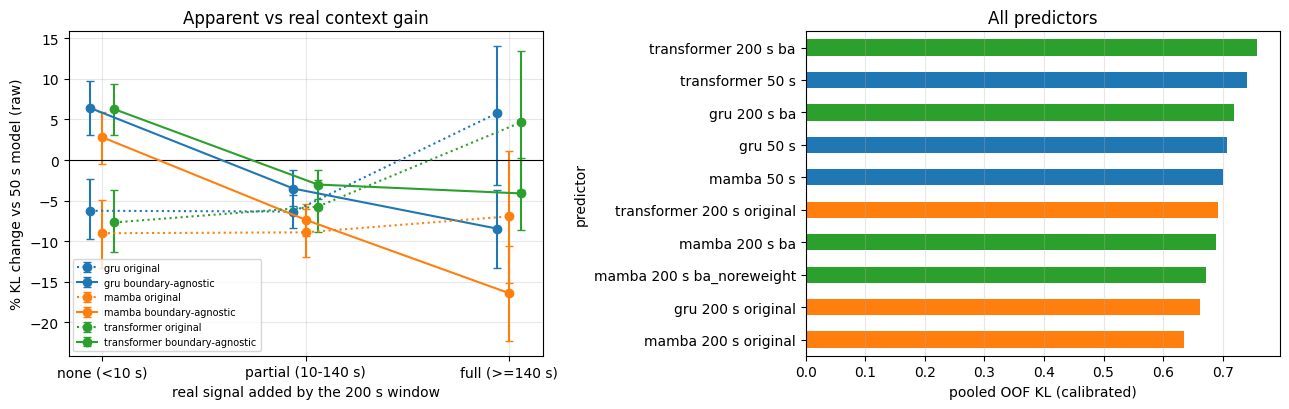

outputs: ['c1_shortcut_removal.csv', 'c2_true_context_gain.csv', 'c3_architecture_ba.csv', 'gru_ba_ctx200_f0.json', 'gru_ba_ctx200_f0.pt', 'gru_ba_ctx200_f0_ba_valpred.npy', 'gru_ba_ctx200_f0_trunc50_valpred.npy', 'gru_ba_ctx200_f1.json', 'gru_ba_ctx200_f1.pt', 'gru_ba_ctx200_f1_ba_valpred.npy', 'gru_ba_ctx200_f1_trunc50_valpred.npy', 'gru_ba_ctx200_f2.json', 'gru_ba_ctx200_f2.pt', 'gru_ba_ctx200_f2_ba_valpred.npy', 'gru_ba_ctx200_f2_trunc50_valpred.npy', 'gru_ba_ctx200_f3.json', 'gru_ba_ctx200_f3.pt', 'gru_ba_ctx200_f3_ba_valpred.npy', 'gru_ba_ctx200_f3_trunc50_valpred.npy', 'gru_ba_ctx200_f4.json', 'gru_ba_ctx200_f4.pt', 'gru_ba_ctx200_f4_ba_valpred.npy', 'gru_ba_ctx200_f4_trunc50_valpred.npy', 'mamba_ba_ctx200_f0.json', 'mamba_ba_ctx200_f0.pt', 'mamba_ba_ctx200_f0_ba_valpred.npy', 'mamba_ba_ctx200_f0_trunc50_valpred.npy', 'mamba_ba_ctx200_f1.json', 'mamba_ba_ctx200_f1.pt', 'mamba_ba_ctx200_f1_ba_valpred.npy', 'mamba_ba_ctx200_f1_trunc50_valpred.npy', 'mamba_ba_ctx200_f2.json', 'mamb

In [15]:
try:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    ax = axes[0]; xs = np.arange(len(CFG["CTX_LABELS"]))
    for i_, name in enumerate(sorted({n_ for n_, _ in CFG["RUNS"]})):
        for lab, ls in ((f"{name} 200 s original", ":"), (f"{name} 200 s ba", "-")):
            sub = c1[(c1.model == lab) & c1.subset.str.startswith("all |")].set_index("subset").reindex([f"all | {b}" for b in CFG["CTX_LABELS"]])
            if len(sub.dropna(how="all")):
                ax.errorbar(xs + (i_ - 1) * 0.06, sub["rel_pct"], yerr=[100 * (sub["diff"] - sub["ci_lo"]) / sub["kl_50s"], 100 * (sub["ci_hi"] - sub["diff"]) / sub["kl_50s"]],
                            fmt="o" + ls, color=f"C{i_}", capsize=3, label=f"{name} {'original' if 'original' in lab else 'boundary-agnostic'}")
    ax.axhline(0, color="k", lw=0.8); ax.set_xticks(xs); ax.set_xticklabels(CFG["CTX_LABELS"])
    ax.set_xlabel("real signal added by the 200 s window"); ax.set_ylabel("% KL change vs 50 s model (raw)")
    ax.set_title("Apparent vs real context gain"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    ax = axes[1]
    s_ = summary.set_index("predictor")["kl_calibrated"]
    s_.plot.barh(ax=ax, color=["C2" if " ba" in k else ("C1" if "original" in k else "C0") for k in s_.index])
    ax.set_xlabel("pooled OOF KL (calibrated)"); ax.set_title("All predictors"); ax.grid(alpha=0.3, axis="x")
    plt.tight_layout(); plt.savefig(f"{CFG['RESULTS_DIR']}/v5_summary.png", dpi=150); plt.show()
except Exception as e:
    print("plot skipped:", e)
print("outputs:", sorted(os.listdir(CFG["RESULTS_DIR"]))[:40])